In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
files = list(Path("../data").rglob("*.xls*"))
print(f'Number of files: {len(files)}')

for file in files:
    print(file)

Number of files: 18
../data/2025/23MARCH25-1MAY25.xls
../data/2025/AUG 2025.xls
../data/2025/DEC 2025.xls
../data/2025/JAN 2025.xls
../data/2025/JULY 2025.xls
../data/2025/JuNE 2025.xls
../data/2025/MAY 2025.xls
../data/2025/NOV2025.xls
../data/2025/OCT 2025.xls
../data/2025/SEP 2025.xls
../data/2026/APR20-MAY42026.xls
../data/2026/August 2026.xls
../data/2026/FEB 2026.xls
../data/2026/JAN 2026.xls
../data/2026/JULY2026.xls
../data/2026/june 2026.xls
../data/2026/MARCH-APR 20.xls
../data/2026/MAY 2026.xls


In [3]:
df = pd.read_csv(files[0], sep='\t')
df.columns

Index(['Date(dd/mm/yy)', 'Time(HH:MM)', 'W Direction(Deg)', 'Temp(Deg C)',
       'R Humidity(%)', 'Solar(CCM)', 'B Pressure(mmHg)', 'Spd(Km/hr)',
       'Rain(mm)', 'Unnamed: 9'],
      dtype='str')

In [4]:
pressure_data = []

for file in files:
    df = pd.read_csv(file, sep="\t")

    df = df[[
        "Date(dd/mm/yy)",
        "Time(HH:MM)",
        "B Pressure(mmHg)"
    ]]

    pressure_data.append(df)

pressure_data = pd.concat(pressure_data, ignore_index=True)

print(pressure_data.shape)
pressure_data.head()

(12692, 3)


,Date(dd/mm/yy),Time(HH:MM),B Pressure(mmHg)
0,24/03/25,13:57,NaN
1,24/03/25,14:00,743.3
2,24/03/25,14:27,NaN
3,24/03/25,14:46,NaN
4,24/03/25,15:23,NaN


In [5]:
print(pressure_data["B Pressure(mmHg)"].value_counts().head(10))

print(
    pressure_data["B Pressure(mmHg)"].isna().sum()
)

B Pressure(mmHg)
742.3    3151
742.1    2246
742.7    1920
742.5    1808
741.9    1024
742.9     648
743.1     156
741.8     103
743.3      99
742.1      88
Name: count, dtype: int64
254


In [6]:
pressure_data["B Pressure(mmHg)"] = pd.to_numeric(
    pressure_data["B Pressure(mmHg)"],
    errors="coerce"
)

pressure_clean = pressure_data.dropna(
    subset=["B Pressure(mmHg)"]
).copy()

print("Valid readings:", len(pressure_clean))
print(pressure_clean["B Pressure(mmHg)"].describe())

Valid readings: 12361
count    12361.000000
mean       741.741582
std          7.072457
min          0.700000
25%        742.100000
50%        742.300000
75%        742.500000
max        744.100000
Name: B Pressure(mmHg), dtype: float64


In [7]:
pressure_clean["Datetime"] = pd.to_datetime(
    pressure_clean["Date(dd/mm/yy)"].astype(str) + " " +
    pressure_clean["Time(HH:MM)"].astype(str),
    dayfirst=True,
    format="mixed",
    errors="coerce"
)

print(
    "Invalid timestamps:",
    pressure_clean["Datetime"].isna().sum()
)

pressure_clean = pressure_clean.dropna(
    subset=["Datetime"]
).copy()

Invalid timestamps: 0


In [8]:
print("Minimum pressure:",
      pressure_clean["B Pressure(mmHg)"].min())

print("Maximum pressure:",
      pressure_clean["B Pressure(mmHg)"].max())

Minimum pressure: 0.7
Maximum pressure: 744.1


In [9]:
duplicate_check = pressure_clean.groupby("Datetime")[
    "B Pressure(mmHg)"
].agg(["count", "nunique"])

duplicate_check = duplicate_check[
    duplicate_check["count"] > 1
]

print("Duplicate timestamps:", len(duplicate_check))

print(
    "Timestamps with conflicting readings:",
    (duplicate_check["nunique"] > 1).sum()
)

Duplicate timestamps: 89
Timestamps with conflicting readings: 0


In [10]:
pressure_clean = pressure_clean.drop_duplicates(
    subset=["Datetime", "B Pressure(mmHg)"]
).copy()

# Exclude the previously identified malformed timestamp
pressure_clean = pressure_clean[
    pressure_clean["Datetime"].dt.year.between(2024, 2026)
].copy()

print("Final observations:", len(pressure_clean))

Final observations: 12271


In [11]:
pressure_clean["Month"] = (
    pressure_clean["Datetime"].dt.to_period("M")
)

monthly_pressure = pressure_clean.groupby("Month").agg(
    Average_Pressure=("B Pressure(mmHg)", "mean"),
    Maximum_Pressure=("B Pressure(mmHg)", "max"),
    Minimum_Pressure=("B Pressure(mmHg)", "min"),
    Observations=("B Pressure(mmHg)", "count")
).reset_index()

print(monthly_pressure.to_string(index=False))

  Month  Average_Pressure  Maximum_Pressure  Minimum_Pressure  Observations
2024-12        732.705150             737.7             728.1           699
2025-01        734.400000             736.5             732.0            55
2025-03        742.170857             743.3             741.9           175
2025-04        742.198594             743.3             741.6           711
2025-05        742.295670             743.9             741.6           739
2025-06        742.248112             743.7             741.0           715
2025-07        742.213594             742.9             741.8           743
2025-08        742.245418             742.9             741.6           742
2025-09        742.319526             743.1             741.9           717
2025-10        742.320974             742.9             741.8           739
2025-11        742.552735             742.9             741.9           713
2025-12        742.740054             743.1             742.3           739
2026-01     

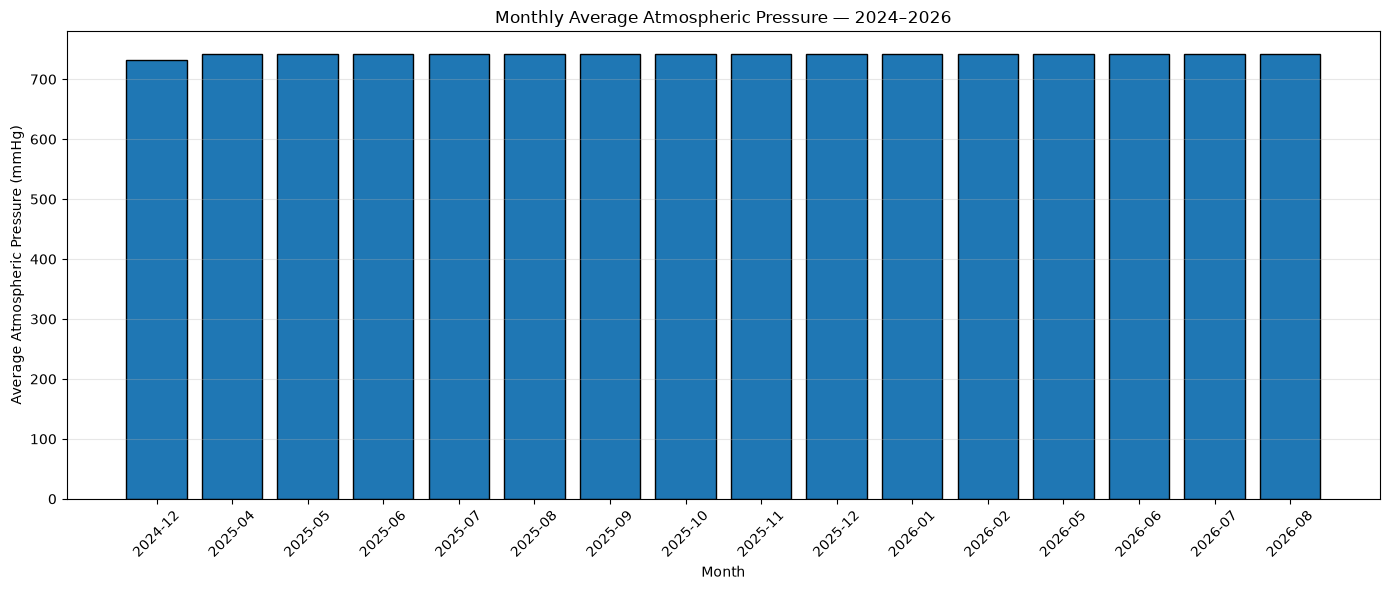

In [12]:
pressure_reliable = monthly_pressure[
    monthly_pressure["Observations"] >= 600
].copy()

pressure_reliable["Month"] = (
    pressure_reliable["Month"].astype(str)
)

plt.figure(figsize=(14, 6))

plt.bar(
    pressure_reliable["Month"],
    pressure_reliable["Average_Pressure"],
    edgecolor="black"
)

plt.xlabel("Month")
plt.ylabel("Average Atmospheric Pressure (mmHg)")
plt.title("Monthly Average Atmospheric Pressure — 2024–2026")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

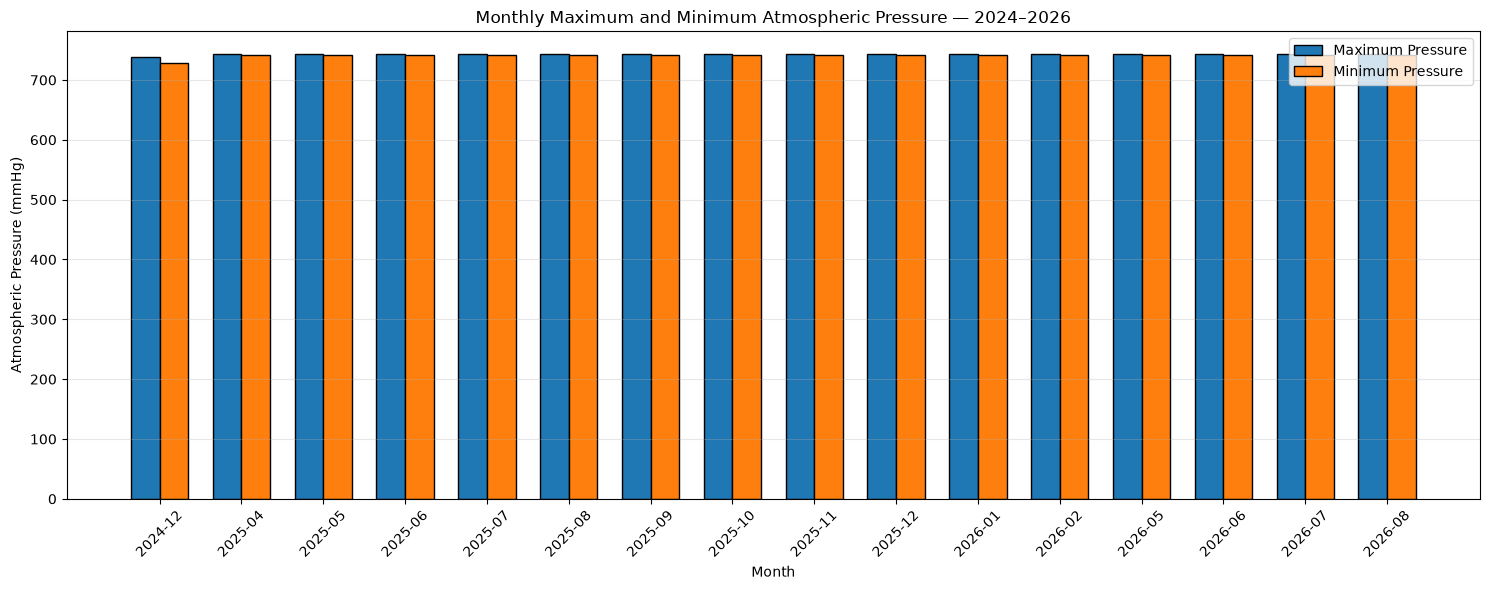

In [13]:
x = np.arange(len(pressure_reliable))
width = 0.35

plt.figure(figsize=(15, 6))

plt.bar(
    x - width/2,
    pressure_reliable["Maximum_Pressure"],
    width,
    label="Maximum Pressure",
    edgecolor="black"
)

plt.bar(
    x + width/2,
    pressure_reliable["Minimum_Pressure"],
    width,
    label="Minimum Pressure",
    edgecolor="black"
)

plt.xlabel("Month")
plt.ylabel("Atmospheric Pressure (mmHg)")
plt.title("Monthly Maximum and Minimum Atmospheric Pressure — 2024–2026")

plt.xticks(x, pressure_reliable["Month"], rotation=45)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
pressure_clean[
    pressure_clean["B Pressure(mmHg)"] < 700
][[
    "Datetime",
    "B Pressure(mmHg)"
]]

,Datetime,B Pressure(mmHg)


In [15]:
pressure_clean = pressure_clean[
    pressure_clean["B Pressure(mmHg)"] >= 700
].copy()

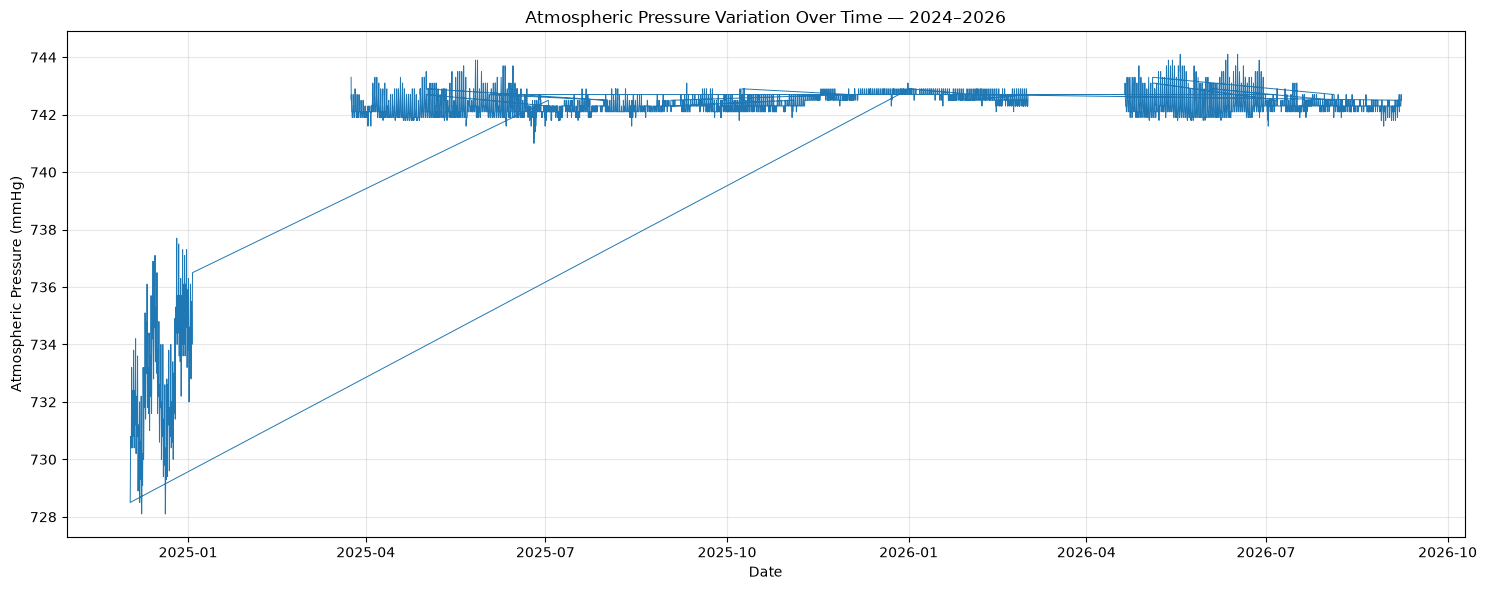

In [16]:
plt.figure(figsize=(15, 6))

plt.plot(
    pressure_clean["Datetime"],
    pressure_clean["B Pressure(mmHg)"],
    linewidth=0.7
)

plt.xlabel("Date")
plt.ylabel("Atmospheric Pressure (mmHg)")
plt.title("Atmospheric Pressure Variation Over Time — 2024–2026")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
pressure_clean["Month"] = (
    pressure_clean["Datetime"].dt.to_period("M")
)

monthly_check = pressure_clean.groupby("Month")[
    "B Pressure(mmHg)"
].agg(
    ["count", "mean", "std", "min", "max"]
)

print(monthly_check.to_string())

         count        mean       std    min    max
Month                                             
2024-12    699  732.705150  2.046725  728.1  737.7
2025-01     55  734.400000  1.109054  732.0  736.5
2025-03    175  742.170857  0.271240  741.9  743.3
2025-04    711  742.198594  0.369656  741.6  743.3
2025-05    739  742.295670  0.413502  741.6  743.9
2025-06    715  742.248112  0.370489  741.0  743.7
2025-07    743  742.213594  0.170984  741.8  742.9
2025-08    742  742.245418  0.169143  741.6  742.9
2025-09    717  742.319526  0.179566  741.9  743.1
2025-10    739  742.320974  0.182147  741.8  742.9
2025-11    713  742.552735  0.168341  741.9  742.9
2025-12    739  742.740054  0.101576  742.3  743.1
2026-01    739  742.707037  0.115255  742.3  742.9
2026-02    667  742.571364  0.154818  742.1  742.9
2026-03     36  742.511111  0.218799  742.3  742.9
2026-04    251  742.439442  0.471082  741.9  743.7
2026-05    740  742.358243  0.524036  741.8  744.1
2026-06    715  742.395245  0.4

In [18]:
transition_data = pressure_clean[
    (pressure_clean["Datetime"] >= "2024-12-01") &
    (pressure_clean["Datetime"] < "2025-05-01")
].sort_values("Datetime")

print(transition_data[
    ["Datetime", "B Pressure(mmHg)"]
].to_string(index=False))

           Datetime  B Pressure(mmHg)
2024-12-02 16:00:00             728.5
2024-12-02 17:00:00             728.7
2024-12-02 18:00:00             729.3
2024-12-02 19:00:00             729.6
2024-12-02 20:00:00             730.4
2024-12-02 21:00:00             730.6
2024-12-02 22:00:00             730.8
2024-12-02 23:00:00             730.6
2024-12-03 00:00:00             730.8
2024-12-03 01:00:00             730.6
2024-12-03 02:00:00             730.4
2024-12-03 03:00:00             730.4
2024-12-03 04:00:00             730.4
2024-12-03 05:00:00             730.4
2024-12-03 06:00:00             730.4
2024-12-03 07:00:00             731.2
2024-12-03 08:00:00             731.8
2024-12-03 09:00:00             732.8
2024-12-03 10:00:00             733.2
2024-12-03 11:00:00             733.0
2024-12-03 12:00:00             732.6
2024-12-03 13:00:00             731.8
2024-12-03 14:00:00             731.2
2024-12-03 15:00:00             730.6
2024-12-03 16:00:00             730.4
2024-12-03 1

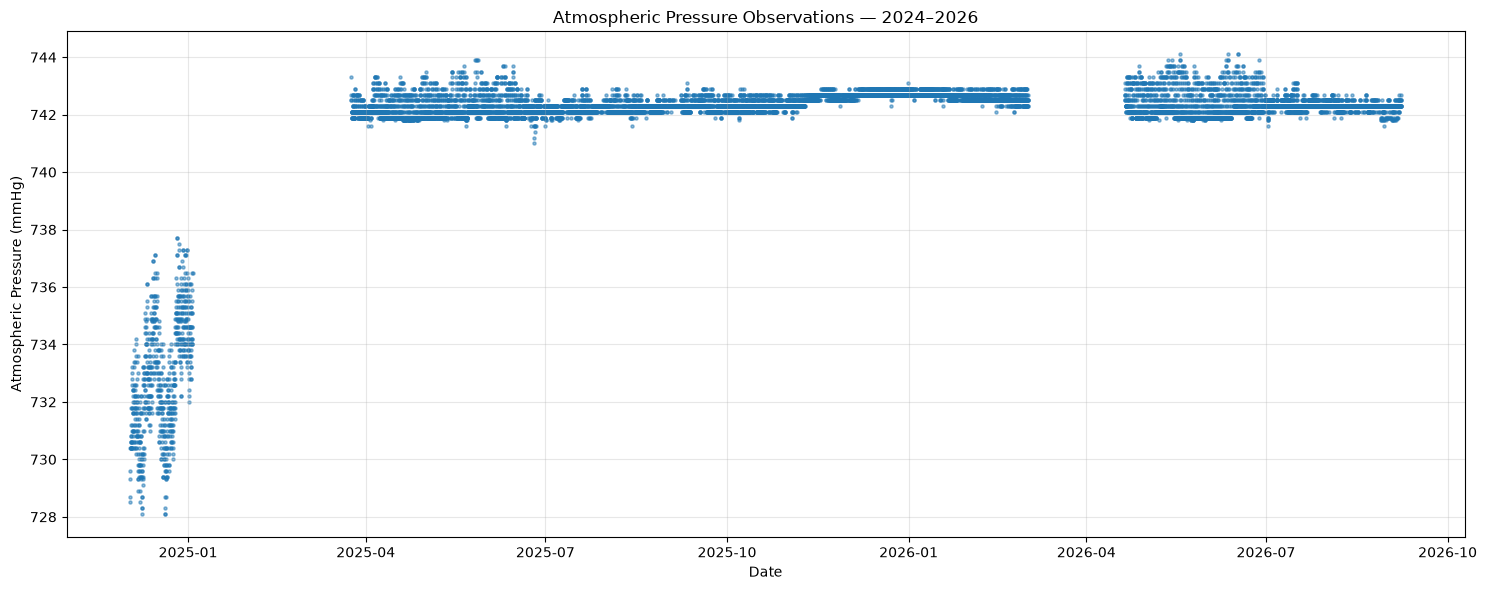

In [19]:
plt.figure(figsize=(15, 6))

plt.scatter(
    pressure_clean["Datetime"],
    pressure_clean["B Pressure(mmHg)"],
    s=5,
    alpha=0.5
)

plt.xlabel("Date")
plt.ylabel("Atmospheric Pressure (mmHg)")
plt.title("Atmospheric Pressure Observations — 2024–2026")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
december_data = pressure_clean[
    pressure_clean["Datetime"].dt.to_period("M") == "2024-12"
].copy()

december_data["Date"] = december_data["Datetime"].dt.date

daily_pressure = december_data.groupby("Date").agg(
    Average_Pressure=("B Pressure(mmHg)", "mean"),
    Minimum_Pressure=("B Pressure(mmHg)", "min"),
    Maximum_Pressure=("B Pressure(mmHg)", "max"),
    Observations=("B Pressure(mmHg)", "count")
).reset_index()

print(daily_pressure.to_string(index=False))

      Date  Average_Pressure  Minimum_Pressure  Maximum_Pressure  Observations
2024-12-02        729.812500             728.5             730.8             8
2024-12-03        731.366667             730.4             733.2            24
2024-12-04        731.700000             730.4             733.8            24
2024-12-05        731.883333             730.2             734.2            24
2024-12-06        731.104167             728.9             733.6            24
2024-12-07        730.200000             728.5             732.0            23
2024-12-08        729.878261             728.1             732.2            23
2024-12-09        731.700000             729.4             733.2            24
2024-12-10        733.308333             731.4             735.1            24
2024-12-11        733.262500             731.8             736.1            24
2024-12-12        732.616667             731.0             734.4            24
2024-12-13        733.758333             731.6      

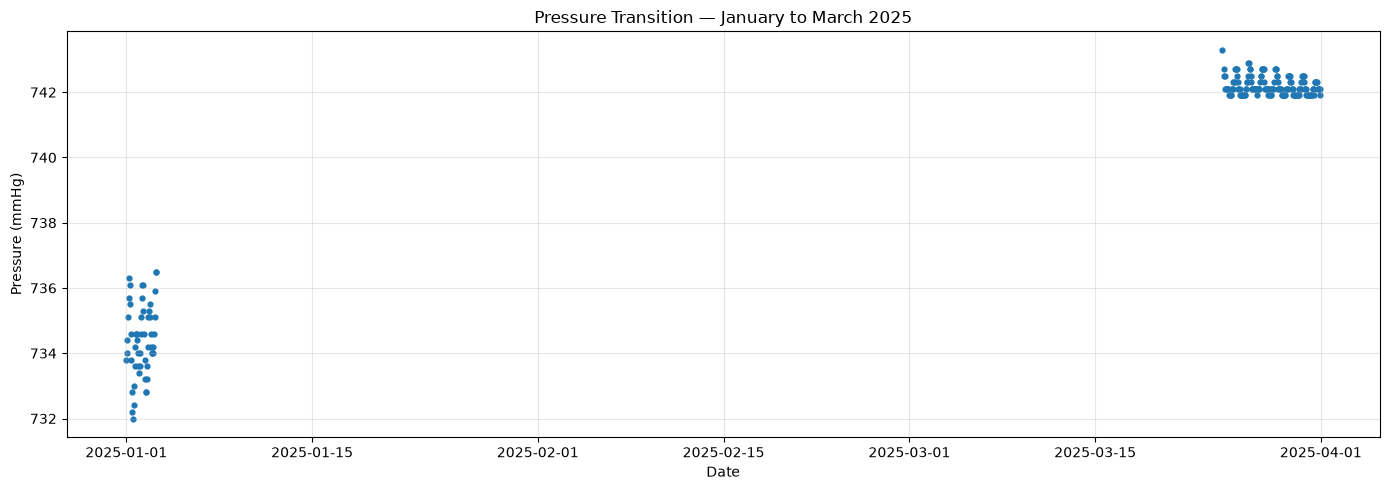

In [21]:
transition = pressure_clean[
    (pressure_clean["Datetime"] >= "2025-01-01") &
    (pressure_clean["Datetime"] < "2025-04-01")
].sort_values("Datetime")

plt.figure(figsize=(14, 5))

plt.scatter(
    transition["Datetime"],
    transition["B Pressure(mmHg)"],
    s=12
)

plt.xlabel("Date")
plt.ylabel("Pressure (mmHg)")
plt.title("Pressure Transition — January to March 2025")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
period_1 = pressure_clean[
    pressure_clean["Datetime"] < "2025-02-01"
]["B Pressure(mmHg)"]

period_2 = pressure_clean[
    pressure_clean["Datetime"] >= "2025-03-01"
]["B Pressure(mmHg)"]

comparison = pd.DataFrame({
    "Dec 2024–Jan 2025": period_1.describe(),
    "Mar 2025 onwards": period_2.describe()
})

print(comparison)

       Dec 2024–Jan 2025  Mar 2025 onwards
count         754.000000      11517.000000
mean          732.828780        742.382860
std             2.041035          0.331429
min           728.100000        741.000000
25%           731.200000        742.100000
50%           732.800000        742.300000
75%           734.400000        742.700000
max           737.700000        744.100000
